<a href="https://colab.research.google.com/github/jimmynewland/moria/blob/main/Morphology_and_Orientation_Research_Inclination_of_AGN_(MORIA)_S%C3%A9rsic_Index.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Morphology and Orientation Research: Inclination of AGN (MORIA)
*Delving Deeper into AGN with WISE and Euclid*

The Euclid Quick Release 1 (Q1) includes a catalog of AGN as one of its preliminary data products. This catalog is missing AGN sources that are included in other catalogs, particularly the WISE AGN catalog. The Euclid team released a preliminary analysis of the Euclid AGN source catalog compared to other known AGN source catalogs. We will initially compare the Euclid Q1 AGN catalog with the WISE AGN catalog. This research will use data analysis and statistical modeling to probe both the overlap and gaps between the Euclid Q1 AGN catalog and other AGN catalogs.

This notebook is meant to compare the Euclid Q1 Deep Field North (EDFN) active galactic nuclei (AGN) candidates across several spaces, including using photometry from the Wide-field Infrared Survey Explorer (WISE) mission to explore how

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import anderson_ksamp
from scipy.stats import kstest
from scipy.stats import PermutationMethod

In [ ]:
from astropy.io import fits
from astropy.table import Table
from astropy.io import ascii
import astropy.units as u
from astropy.units import def_unit, add_enabled_units

##Load AGN data for Euclid Q1
This table was created by using TOPCAT to join the data from Q1 for EDFN which contain Sérsic indexes and other morphological parameters with the WISE catalog across all color indexes. The table was saved in FITS format using the AstroPy API and then converted to a pandas dataframe.

In [ ]:
file_path = "https://thinkingwithcode.com/datascience/edfn-with-wise-and-sersic-indexes.fits"
table = Table.read(file_path, format='fits')
df = table.to_pandas()

##Scatter Plots for AGN Fraction
See https://iopscience.iop.org/article/10.3847/1538-4365/aaa00a

In [ ]:
order = ['Q1 AGN', 'DESI AGN', 'WISE AGN']
colors = sns.color_palette('viridis_r', n_colors=len(order))
palette = dict(zip(order, colors))

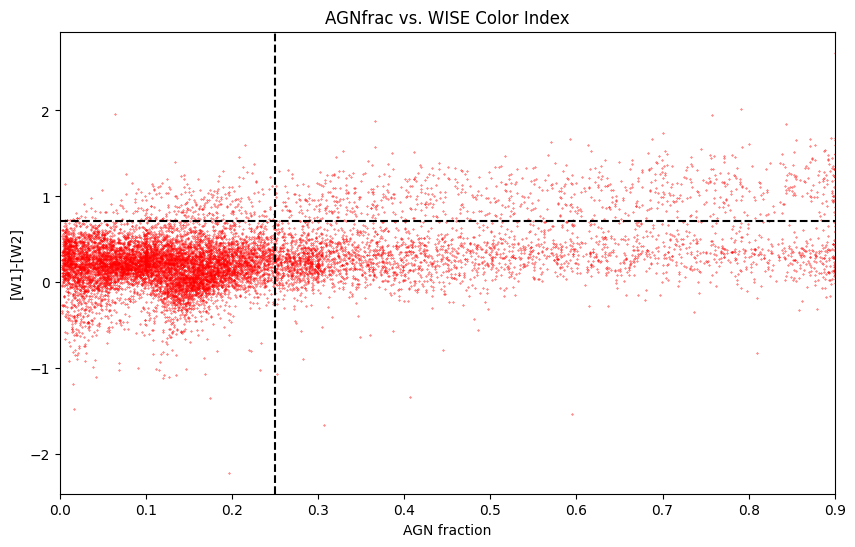

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(df['AGNfrac'],df['w1-w2'], s=0.1, color='red')
plt.xlabel('AGN fraction')
plt.ylabel('[W1]-[W2]')
plt.xlim(0,0.9)
plt.title('AGNfrac vs. WISE Color Index')
plt.axvline(x=0.25, color='black', linestyle='--')  # Add vertical line at AGNfrac = 0.25
plt.axhline(y=0.71, color='black', linestyle='--')   # Add horizontal line at w1-w2 = 0.71
plt.show()

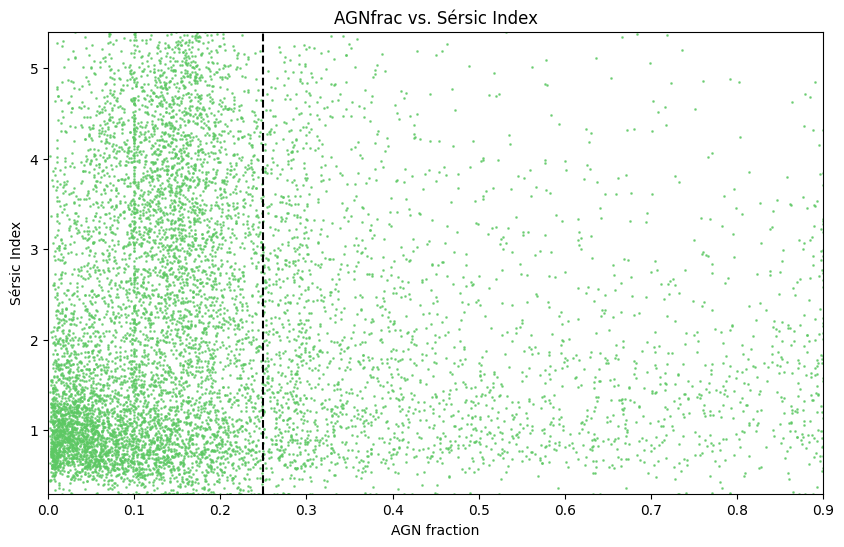

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(df['AGNfrac'],df['sersic_sersic_vis_index'], s=0.9, color=palette['Q1 AGN'], alpha=0.7)
plt.xlabel('AGN fraction')
plt.ylabel('Sérsic Index')
plt.xlim(0,0.9) # Euclid AGN thresholds
plt.ylim(0.3,5.4) # Euclid AGN thresholds
plt.title('AGNfrac vs. Sérsic Index')
plt.axvline(x=0.25, color='black', linestyle='--')  # Add vertical line at AGNfrac = 0.25
plt.show()

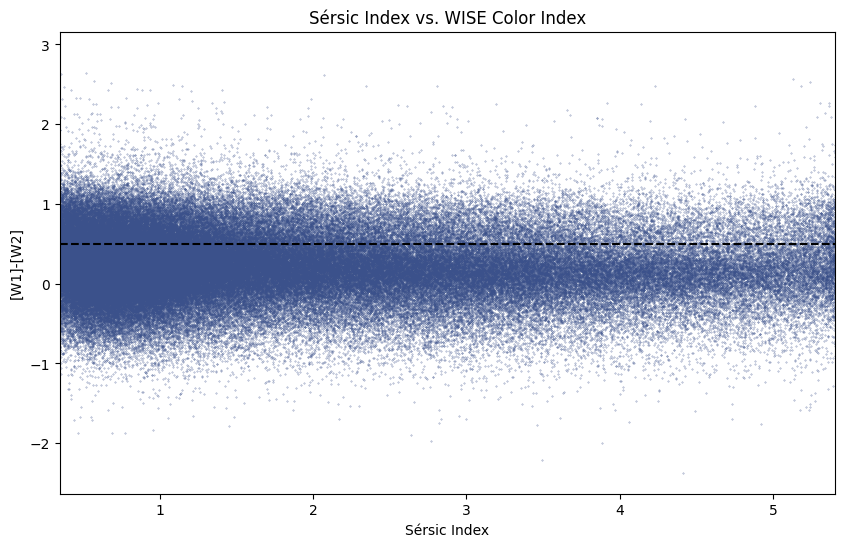

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(df['sersic_sersic_vis_index'],df['w1-w2'], s=0.09, color=palette['WISE AGN'], alpha=0.7)
plt.xlabel('Sérsic Index')
plt.ylabel('[W1]-[W2]')
plt.xlim(0.35,5.4) # Euclid AGN thresholds
#plt.ylim(0.3,5.4) # Euclid AGN thresholds
plt.title('Sérsic Index vs. WISE Color Index')
plt.axhline(y=0.5, color='black', linestyle='--')   # Add horizontal line at w1-w2 = 0.5
plt.show()

##Dataframe of AGN Candidates also found in DESI
This dataframe is a subset of the Q1 AGN candidate list where the DESI column contained any reference. This way we can compare the entire dataset to those AGN found in the DESI catalog.

In [ ]:
df_sersic_inDESI = df.dropna(subset=['DESI'])

##Dataframe of AGN Candidates from WISE R90
This dataframe is a subset of the Q1 AGN candidate list which were included in the WISE R90 catalog.

In [ ]:
df_sersic_inWISEr90 = df[df['R90AGNCand'] == 1]

In [ ]:
df_sersic_notWISEr90 = df[df['R90AGNCand'] == 0]

In [ ]:
print(f"Total number of Euclid Q1 AGN candidates: {len(df)}.")
print(f"Number of Euclid Q1 AGN candidates in DESI catalog: {len(df_sersic_inDESI)}.")
print(f"Number of Euclid Q1 AGN candidates in WISE R90 catalog: {len(df_sersic_inWISEr90)}.")

Total number of Euclid Q1 AGN candidates: 266029.
Number of Euclid Q1 AGN candidates in DESI catalog: 11664.
Number of Euclid Q1 AGN candidates in WISE R90 catalog: 1220.


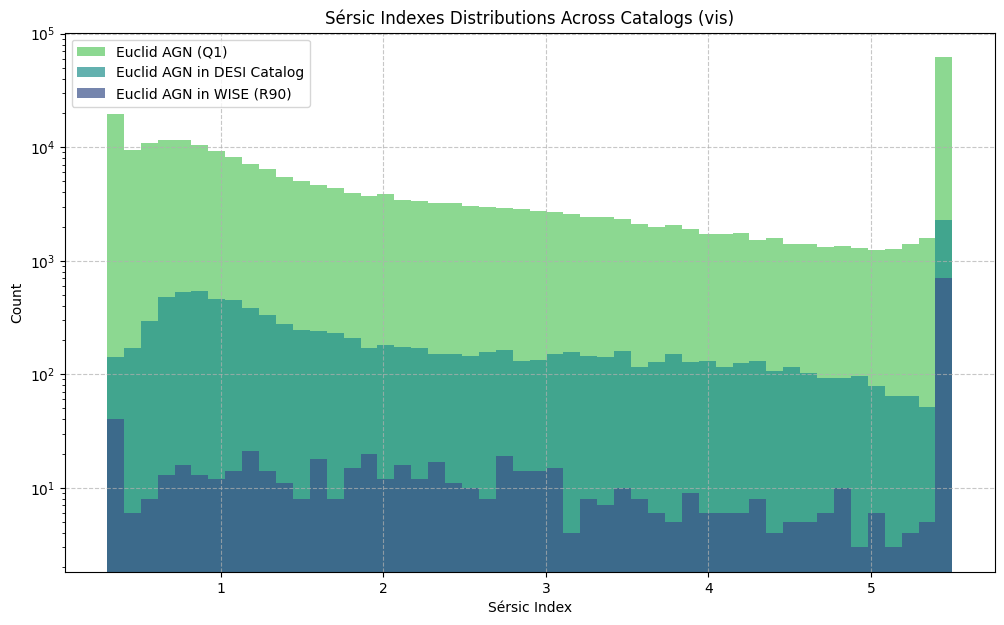

In [ ]:
plt.figure(figsize=(12, 7))
bins = 50
plt.hist(df['sersic_sersic_vis_index'], bins=bins, alpha=0.7, color=palette['Q1 AGN'], label='Euclid AGN (Q1)', log=True)
plt.hist(df_sersic_inDESI['sersic_sersic_vis_index'], bins=bins, alpha=0.7, color=palette['DESI AGN'], label='Euclid AGN in DESI Catalog',log=True)
plt.hist(df_sersic_inWISEr90['sersic_sersic_vis_index'], bins=bins, alpha=0.7, color=palette['WISE AGN'], label='Euclid AGN in WISE (R90)',log=True)

plt.title('Sérsic Indexes Distributions Across Catalogs (vis)')
plt.xlabel('Sérsic Index')
plt.ylabel('Count')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

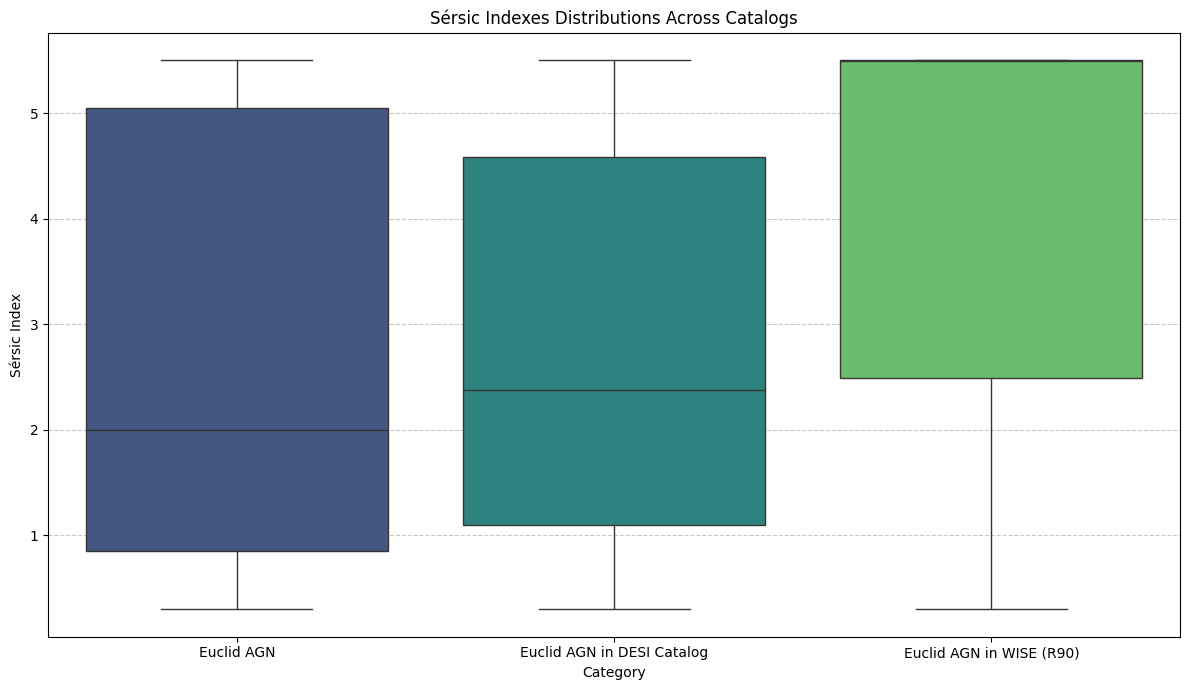

In [ ]:
df_combined = pd.DataFrame({
    'Sérsic Index': pd.concat([
        df['sersic_sersic_vis_index'],
        df_sersic_inDESI['sersic_sersic_vis_index'],
        df_sersic_inWISEr90['sersic_sersic_vis_index']
    ]),
    'Category':
        ['Euclid AGN'] * len(df) +
        ['Euclid AGN in DESI Catalog'] * len(df_sersic_inDESI) +
        ['Euclid AGN in WISE (R90)'] * len(df_sersic_inWISEr90)
})

plt.figure(figsize=(12, 7))
sns.boxplot(x='Category', y='Sérsic Index', data=df_combined, palette='viridis', hue='Category', legend=False)
plt.title('Sérsic Indexes Distributions Across Catalogs')
plt.ylabel('Sérsic Index')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Statisitcal Test for Sérsic Parameter Distributions

In [ ]:
# Extract only the Sérsic parameters from the larger dataset
sersic_notWISEr90 = df_sersic_notWISEr90['sersic_sersic_vis_index'].dropna()
sersic_inWISEr90 = df_sersic_inWISEr90['sersic_sersic_vis_index'].dropna()
sersic_inDESI = df_sersic_inDESI['sersic_sersic_vis_index'].dropna()

### Anderson-Darling Test WISE and not WISE
https://asaip.psu.edu/articles/beware-the-kolmogorov-smirnov-test/
The literature showed that 1000 resamples as a bootstrap technique was sufficient, and so it is used here.

Critial value interpretation: from here https://www.tandfonline.com/doi/abs/10.1080/01621459.1987.10478517

Beware the large sample sizes can inflate the significance of the difference in the population means. The more important fact is that the critical values imply that the populations are indeed different.

In [ ]:
statistic, critical_values, significance_level = anderson_ksamp([sersic_notWISEr90,sersic_inWISEr90], method=PermutationMethod(n_resamples=1000))

print(f"Anderson-Darling Statistic: {statistic:.4f}")
print(f"Critical Values: {critical_values}")
print(f"Significance Level: {significance_level:.4f}")

if significance_level < 0.05:
    print(f"The two distributions are significantly different at the (reject the null hypothesis).")
else:
    print(f"There is no significant difference between the two distributions (fail to reject the null hypothesis).")

Anderson-Darling Statistic: 451.7485
Critical Values: [0.325 1.226 1.961 2.718 3.752 4.592 6.546]
Significance Level: 0.0010
The two distributions are significantly different at the (reject the null hypothesis).


### Kolmogorov-Smirnov Test WISE and not WISE


In [ ]:
ks_statistic, p_value = kstest(sersic_notWISEr90,sersic_inWISEr90)

print(f"Kolmogorov-Smirnov Statistic: {ks_statistic:.4f}")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print(f"The two distributions are significantly different (reject the null hypothesis).")
else:
    print(f"There is no significant difference between the two distributions (fail to reject the null hypothesis).")

Kolmogorov-Smirnov Statistic: 0.3455
P-value: 0.0000
The two distributions are significantly different (reject the null hypothesis).


## Filtered Sérsic Indexes (0.35 < Sérsic < 5)

In [ ]:
ser_notW90_filt = sersic_notWISEr90.loc[sersic_notWISEr90.between(0.35, 5)]
ser_inW90_filt = sersic_inWISEr90.loc[sersic_inWISEr90.between(0.35, 5)]
ser_inDESI_filt = sersic_inDESI.loc[sersic_inDESI.between(0.35, 5)]

In [ ]:
order = ['Q1 AGN', 'DESI AGN', 'WISE AGN']
colors = sns.color_palette('viridis_r', n_colors=len(order))
palette = dict(zip(order, colors))

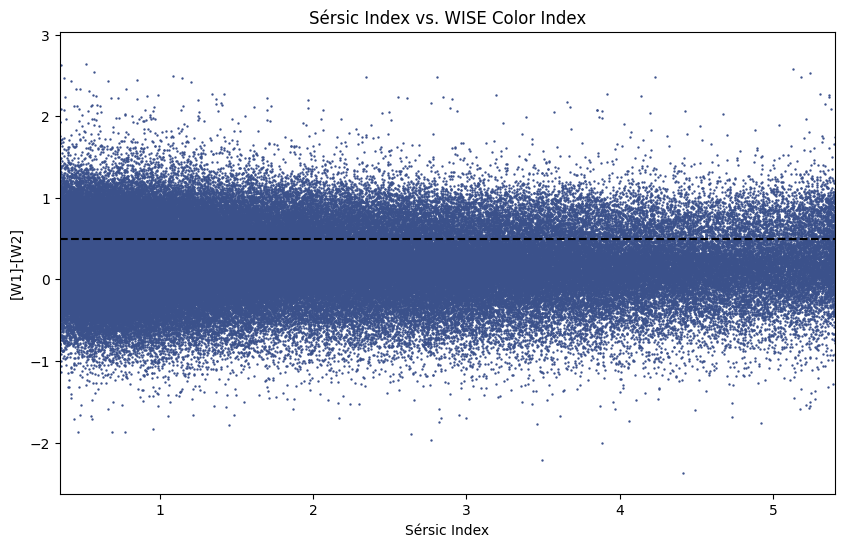

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(df_sersic_notWISEr90['sersic_sersic_vis_index'],df_sersic_notWISEr90['w1-w2'], s=0.5, color=palette['WISE AGN'])
plt.xlabel('Sérsic Index')
plt.ylabel('[W1]-[W2]')
plt.xlim(0.35,5.4) # Euclid AGN thresholds
plt.title('Sérsic Index vs. WISE Color Index')
plt.axhline(y=0.5, color='black', linestyle='--')   # Add horizontal line at w1-w2 = 0.5
plt.show()

In [ ]:
df_filtered_combined = pd.DataFrame({
    'Sérsic Index': pd.concat([
        ser_notW90_filt,
        ser_inDESI_filt,
        ser_inW90_filt
    ]),
    'Category':
        ['Q1 AGN'] * len(ser_notW90_filt) +
        ['DESI AGN'] * len(ser_inDESI_filt) +
        ['WISE AGN'] * len(ser_inW90_filt)
})

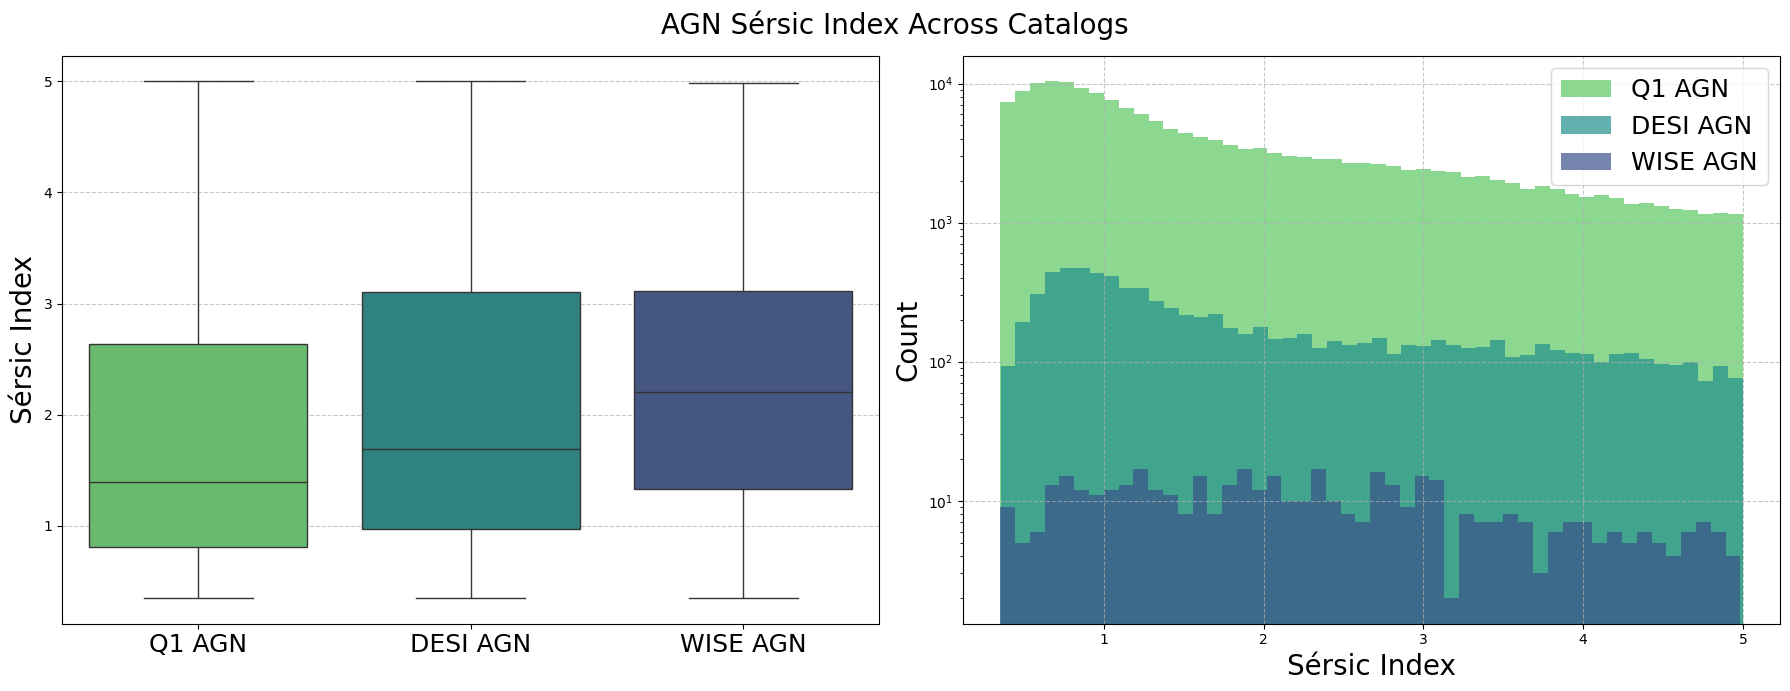

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7)); titleSize = 20
fig.suptitle('AGN Sérsic Index Across Catalogs', fontsize=titleSize)

sns.boxplot(x='Category', y='Sérsic Index', data=df_filtered_combined,
            order=order, palette=palette, hue='Category', legend=False, ax=axes[0])
axes[0].set_xlabel('')
axes[0].set_ylabel('Sérsic Index', fontsize=titleSize)
axes[0].tick_params(axis='x', labelsize=18)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

bins = 50
axes[1].hist(ser_notW90_filt, bins=bins, alpha=0.7, color=palette['Q1 AGN'],   label='Q1 AGN',   log=True)
axes[1].hist(ser_inDESI_filt, bins=bins, alpha=0.7, color=palette['DESI AGN'], label='DESI AGN', log=True)
axes[1].hist(ser_inW90_filt,  bins=bins, alpha=0.7, color=palette['WISE AGN'], label='WISE AGN', log=True)
axes[1].set_xlabel('Sérsic Index', fontsize=titleSize)
axes[1].set_ylabel('Count', fontsize=titleSize)
axes[1].legend(fontsize=18)
axes[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [ ]:
statistic, critical_values, significance_level = anderson_ksamp([ser_notW90_filt,ser_inW90_filt], method=PermutationMethod(n_resamples=1000))

print("Test between Q1 Sérsic indexes and those from the WISE R90 catalog")
print(f"Anderson-Darling Statistic: {statistic:.4f}")
print(f"Critical Values: {critical_values}")
print(f"Significance Level: {significance_level:.4f}")

if significance_level < 0.05:
    print(f"The two distributions are significantly different at the (reject the null hypothesis).")
else:
    print(f"There is no significant difference between the two distributions (fail to reject the null hypothesis).")

Test between Q1 Sérsic indexes and those from the WISE R90 catalog
Anderson-Darling Statistic: 68.7131
Critical Values: [0.325 1.226 1.961 2.718 3.752 4.592 6.546]
Significance Level: 0.0010
The two distributions are significantly different at the (reject the null hypothesis).


In [ ]:
stat, crit_vals, sig_lvl = anderson_ksamp([ser_notW90_filt,ser_inDESI_filt],
                                          method=PermutationMethod(n_resamples=100))
print("Test between Q1 Sérsic indexes and those from the DESI catalog")
print(f"Anderson-Darling Statistic: {stat:.4f}")
print(f"Critical Values: {crit_vals}")
print(f"Significance Level: {sig_lvl:.4f}")

if sig_lvl < 0.05:
    print(f"Q1 AGN & WISE AGN Sérsic index distributions vary significantly.")
else:
    print(f"Q1 AGN & WISE AGN Sérsic index distributions do not vary significantly.")

Test between Q1 Sérsic indexes and those from the DESI catalog
Anderson-Darling Statistic: 270.3843
Critical Values: [0.325 1.226 1.961 2.718 3.752 4.592 6.546]
Significance Level: 0.0099
Q1 AGN & WISE AGN Sérsic index distributions vary significantly.


In [ ]:
ks_statistic, p_value = kstest(ser_notW90_filt,ser_inW90_filt)

print(f"Kolmogorov-Smirnov Statistic: {ks_statistic:.4f}")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print(f"Q1 AGN & WISE AGN Sérsic index distributions vary significantly.")
else:
    print(f"Q1 AGN & WISE AGN Sérsic index distributions do not vary significantly.")

Kolmogorov-Smirnov Statistic: 0.2389
P-value: 0.0000
Q1 AGN & WISE AGN Sérsic index distributions vary significantly.
